# Détection de faux billets

**Mission :** construire un algorithme capable de différencier automatiquement
les vrais des faux billets à partir de leurs dimensions géométriques.

**Données :** 1 500 billets déjà scannés (1 000 vrais, 500 faux) avec 6 dimensions



**Algorithmes à tester**  : régression logistique,
k-means, KNN et random forest.

**Plan :**
1. Chargement et première exploration des données
2. Traitement des valeurs manquantes
3. Analyse descriptive
4. Préparation des données pour la modélisation
5. Entraînement et évaluation des 4 algorithmes
6. Comparaison et choix du modèle final
7. Sauvegarde du modèle pour l'application  
8. Test sur fichier et manuel

## 1. Chargement données et exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


# Chargement du fichier (les colonnes sont séparées par des ";")
df = pd.read_csv("billets.csv", sep=";")
df.head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [2]:
print("Dimensions du tableau :", df.shape)

# Nombre de vrais et de faux billets
print("\nRépartition vrai / faux :")
print(df["is_genuine"].value_counts())
print("\nEn pourcentage :")
print((df["is_genuine"].value_counts(normalize=True) * 100).round(1))

Dimensions du tableau : (1500, 7)

Répartition vrai / faux :
is_genuine
True     1000
False     500
Name: count, dtype: int64

En pourcentage :
is_genuine
True     66.7
False    33.3
Name: proportion, dtype: float64


In [3]:
# Vérification des valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isna().sum())

Valeurs manquantes par colonne :
is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64


## 2. Traitement des valeurs manquantes

37 valeurs manquantes dans la colonne `margin_low
on les conserve pour ne pas perdre d'information.

**Méthode choisie : l'imputation par régression linéaire.**
Avec la regression linéaire on utilise les dimensions des billets pour predire les dimensions du `margin_low`
Entrainement de la Regressions lineare sur les billets qui sont deja prets et puis prediction.
Cela bcq mieux que la moyenne.

In [4]:
# valeurs manquantes entre faux et vrais
print("Nature des billets avec margin_low manquant :")
print(df[df["margin_low"].isna()]["is_genuine"].value_counts())

Nature des billets avec margin_low manquant :
is_genuine
True     29
False     8
Name: count, dtype: int64


In [5]:
from sklearn.linear_model import LinearRegression

# Billets avec / sans valeur connue
connus = df[df["margin_low"].notna()]
inconnus = df[df["margin_low"].isna()]

# On prédit margin_low à partir des 5 autres dimensions
variables_explicatives = ["diagonal", "height_left", "height_right",
                          "margin_up", "length"]
reg_imputation = LinearRegression()
reg_imputation.fit(connus[variables_explicatives], connus["margin_low"])

# R² : mesure la qualité de la régression (1 = parfait, 0 = nul)
print(f"R² de la régression d'imputation : "
      f"{reg_imputation.score(connus[variables_explicatives], connus['margin_low']):.3f}")

# On remplit les trous avec les valeurs prédites
df.loc[df["margin_low"].isna(), "margin_low"] = reg_imputation.predict(
    inconnus[variables_explicatives])

print("Valeurs manquantes restantes :", int(df.isna().sum().sum()))

R² de la régression d'imputation : 0.477
Valeurs manquantes restantes : 0


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


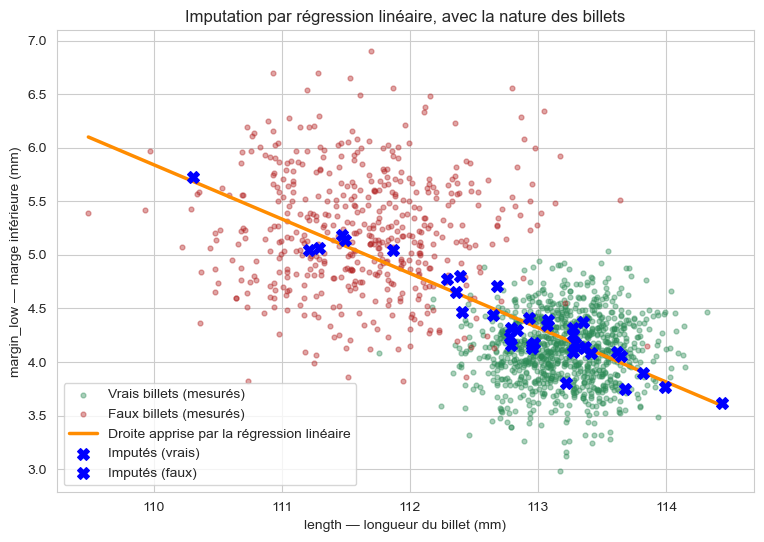

In [6]:
# Même graphique, avec la nature des billets en couleur
# (vert = vrai billet, rouge = faux billet ; X = valeurs imputées)

reg_graphique = LinearRegression()
reg_graphique.fit(connus[["length"]], connus["margin_low"])

x_droite = np.linspace(df["length"].min(), df["length"].max(), 100).reshape(-1, 1)
y_droite = reg_graphique.predict(x_droite)

plt.figure(figsize=(9, 6))

# 1) Billets complets, colorés selon leur nature
for vrai, couleur, etiquette in [(True, "seagreen", "Vrais billets (mesurés)"),
                                 (False, "firebrick", "Faux billets (mesurés)")]:
    sous_groupe = connus[connus["is_genuine"] == vrai]
    plt.scatter(sous_groupe["length"], sous_groupe["margin_low"],
                s=12, alpha=0.4, color=couleur, label=etiquette)

# 2) La droite de régression
plt.plot(x_droite, y_droite, color="darkorange", linewidth=2.5,
         label="Droite apprise par la régression linéaire")

# 3) Les 37 valeurs imputées, colorées selon leur nature
for vrai, couleur, etiquette in [(True, "b", "Imputés (vrais)"),
                                 (False, "b", "Imputés (faux)")]:
    masque = inconnus["is_genuine"] == vrai
    plt.scatter(inconnus.loc[masque, "length"],
                df.loc[inconnus.index[masque], "margin_low"],
                marker="X", s=70, color=couleur, zorder=5, label=etiquette)

plt.xlabel("length — longueur du billet (mm)")
plt.ylabel("margin_low — marge inférieure (mm)")
plt.title("Imputation par régression linéaire, avec la nature des billets")
plt.legend()
plt.show()


## 3. Analyse descriptive

Objectif : comprendre comment les dimensions se répartissent et repérer
visuellement les différences entre vrais et faux billets.

In [7]:
# Statistiques descriptives par classe (moyenne, écart-type, min, max...)
df.groupby("is_genuine")[["diagonal", "height_left", "height_right",
                          "margin_low", "margin_up", "length"]].describe().T.round(2)

is_genuine           False    True 
diagonal     count  500.00  1000.00
             mean   171.90   171.99
             std      0.31     0.30
             min    171.04   171.04
             25%    171.69   171.79
             50%    171.91   171.99
             75%    172.09   172.20
             max    173.01   172.92
height_left  count  500.00  1000.00
             mean   104.19   103.95
             std      0.22     0.30
             min    103.51   103.14
             25%    104.04   103.74
             50%    104.18   103.95
             75%    104.33   104.14
             max    104.88   104.86
height_right count  500.00  1000.00
             mean   104.14   103.81
             std      0.27     0.29
             min    103.43   102.82
             25%    103.95   103.61
             50%    104.16   103.81
             75%    104.32   104.00
             max    104.95   104.95
margin_low   count  500.00  1000.00
             mean     5.21     4.12
             std      0.55     0.32
             min      3.82     2.98
             25%      4.84     3.91
             50%      5.18     4.12
             75%      5.59     4.34
             max      6.90     5.04
margin_up    count  500.00  1000.00
             mean     3.35     3.05
             std      0.18     0.19
             min      2.92     2.27
             25%      3.22     2.93
             50%      3.35     3.05
             75%      3.47     3.18
             max      3.91     3.74
length       count  500.00  1000.00
             mean   111.63   113.20
             std      0.62     0.36
             min    109.49   111.76
             25%    111.20   112.95
             50%    111.63   113.20
             75%    112.03   113.46
             max    113.85   114.44

Différences nettes sur les moyennes :   
- `length` moyenne est plus faible pour les faux billets (~111,6 mm contre
~113,2 mm)   
- `margin_low` est plus grande (~5,2 mm contre ~4,1 mm).

Dans des graphiques est plus evidenet que sur un tableau

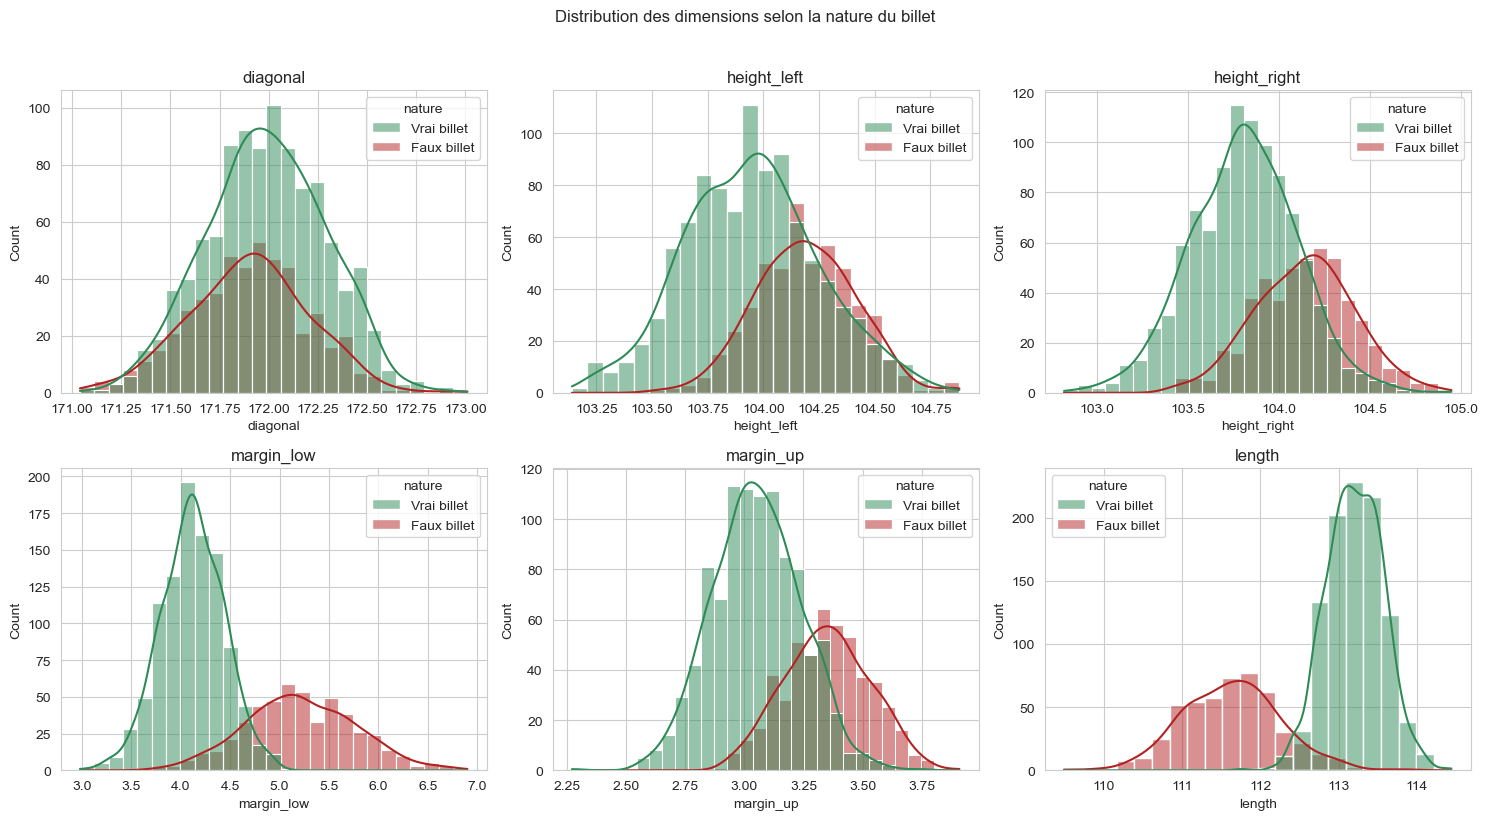

In [8]:
# Colonne texte pour avoir de jolies légendes sur les graphiques
df["nature"] = np.where(df["is_genuine"], "Vrai billet", "Faux billet")
COLS = ["diagonal", "height_left", "height_right",
        "margin_low", "margin_up", "length"]

# Histogrammes de chaque dimension, colorés selon la nature du billet
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), COLS):
    sns.histplot(data=df, x=col, hue="nature", kde=True, ax=ax,
                 palette={"Vrai billet": "seagreen", "Faux billet": "firebrick"})
    ax.set_title(col)
plt.suptitle("Distribution des dimensions selon la nature du billet", y=1.02)
plt.tight_layout()
plt.show()

- `length`, `margin_low` et `margin_up` se chevauchent peu entre vrais et faux billets = **bons candidats** pour séparer les deux classes  
- `diagonal`, `height_left` et `height_right` se recouvrent beaucoup = "mauvais candidats"

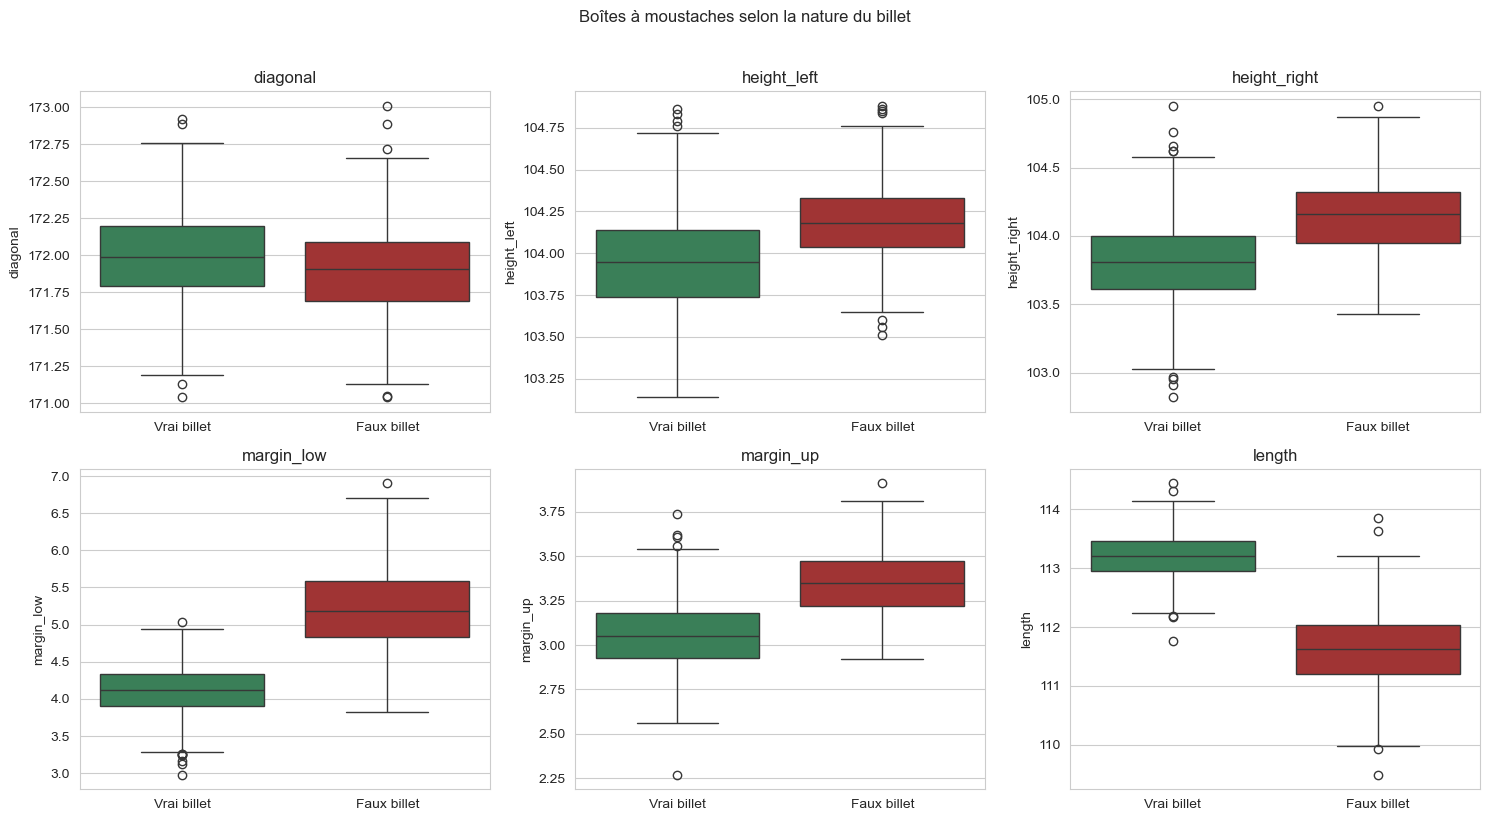

In [9]:
# Boîtes à moustaches : même lecture, en plus synthétique
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), COLS):
    sns.boxplot(data=df, x="nature", y=col, hue="nature", ax=ax, legend=False,
                palette={"Vrai billet": "seagreen", "Faux billet": "firebrick"})
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boîtes à moustaches selon la nature du billet", y=1.02)
plt.tight_layout()
plt.show()

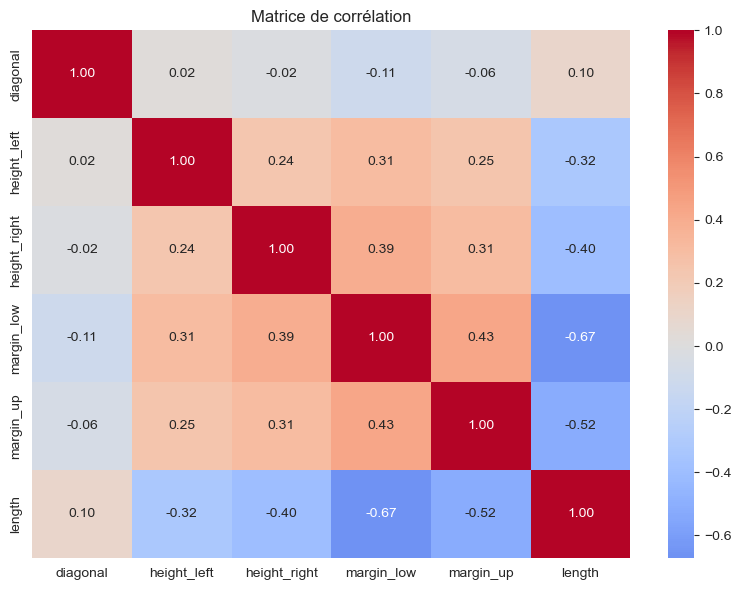

In [10]:
# Matrice de corrélation entre les 6 dimensions
plt.figure(figsize=(8, 6))
corr = df[COLS].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

### Visualisation par ACP
On résume les 6 dimensions en seulement 2 axes pour avoir un graph de comment les billets se séparent entre `Vrai` et `Faux`


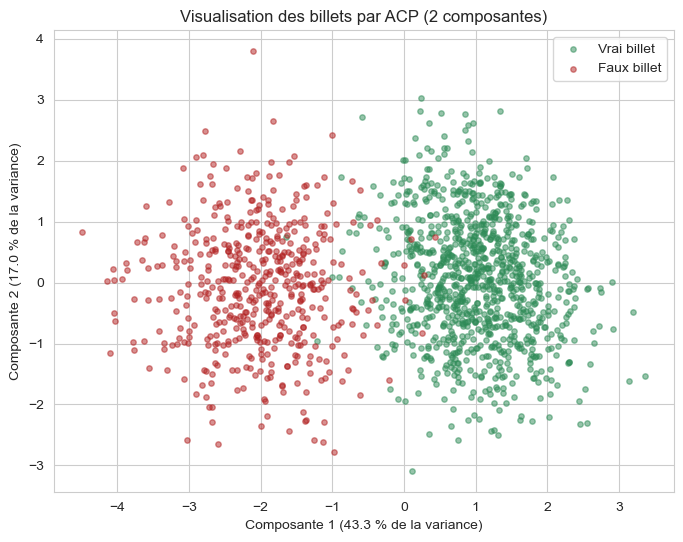

Variance totale conservée par les 2 composantes : 60.2 %


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[COLS]
y = df["is_genuine"]

# Standardisation puis ACP à 2 composantes
X_std_visu = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std_visu)

plt.figure(figsize=(8, 6))
for nature, couleur in [("Vrai billet", "seagreen"), ("Faux billet", "firebrick")]:
    masque = (df["nature"] == nature).to_numpy()
    plt.scatter(X_pca[masque, 0], X_pca[masque, 1],
                c=couleur, label=nature, alpha=0.5, s=15)
plt.xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]*100:.1f} % de la variance)")
plt.ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]*100:.1f} % de la variance)")
plt.title("Visualisation des billets par ACP (2 composantes)")
plt.legend()
plt.show()

print(f"Variance totale conservée par les 2 composantes : "
      f"{pca.explained_variance_ratio_.sum()*100:.1f} %")

`Vrai` et `Faux` sont **netttement séparés** et petite zone de chevauchement. 
Donc les 6 dims permettent d identifier les vrais du faux

## 4. Préparation des données pour la modélisation

Deux étapes classiques avant d'entraîner un modèle :

1. **Découpage entraînement / test (75 % / 25 %).** On entraîne les modèles
   sur une partie des données   
   et on les évalue sur des billets qu'ils n'ont
   jamais vus : seule façon honnête de mesurer leur capacité à
   généraliser.  
   `stratify` = garde la proportion vrai/faux (2/3 - 1/3) les deux jeux.
2. **Standardisation.** La régression logistique, le k-means et le KNN sont
   sensibles à l'échelle des variables :   
   on centre-réduit donc les données
   (le scaler est ajusté **uniquement sur le jeu d'entraînement** pour éviter
   toute fuite d'information).   

   Le **random forest**, basé sur des arbres, n'en a
   pas besoin.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print(f"Jeu d'entraînement : {len(X_train)} billets "
      f"({int(y_train.sum())} vrais, {int((~y_train).sum())} faux)")
print(f"Jeu de test        : {len(X_test)} billets "
      f"({int(y_test.sum())} vrais, {int((~y_test).sum())} faux)")

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

Jeu d'entraînement : 1125 billets (750 vrais, 375 faux)
Jeu de test        : 375 billets (250 vrais, 125 faux)


### Comment évaluer les modèles ?

Pour chaque algorithme on calculera :

- la **matrice de confusion** cela compte :  
  - vrais positifs, 
  - vrais négatifs,
  - **faux positifs** (vrai billet classé faux)
  - **faux négatifs** (faux billet
  classé vrai — l'erreur la plus grave/importante) ;
- l'**accuracy** : proportion de prédictions correctes ;
- la **précision** (classe « faux ») : parmi les billets détectés comme faux,
  combien le sont vraiment ;
- le **rappel** (classe « faux ») : parmi tous les faux billets, combien en
  détecte-t-on — c'est **la métrique prioritaire** ici, car un faux billet qui
  passe inaperçu coûte plus cher qu'un vrai billet vérifié à tort ;
- le **score F1** : moyenne harmonique de précision et rappel.

## 5. Entraînement et évaluation des 4 algorithmes

In [13]:
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score, f1_score)

def evaluer(nom, y_true, y_pred):
    """Affiche les métriques d'un modèle et les renvoie dans un dictionnaire."""
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_faux": precision_score(y_true, y_pred, pos_label=False),
        "recall_faux": recall_score(y_true, y_pred, pos_label=False),
        "f1_faux": f1_score(y_true, y_pred, pos_label=False),
        "matrice": confusion_matrix(y_true, y_pred, labels=[True, False]),
    }
    print(f"=== {nom} ===")
    print(f"Accuracy          : {m['accuracy']:.4f}")
    print(f"Précision (faux)  : {m['precision_faux']:.4f}")
    print(f"Rappel (faux)     : {m['recall_faux']:.4f}")
    print(f"F1 (faux)         : {m['f1_faux']:.4f}")
    print("Matrice de confusion (lignes = réel [Vrai, Faux]) :")
    print(m["matrice"])
    return m

resultats_modeles = {}

### 5.1 Régression logistique

algorithme de classification

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train_std, y_train)

resultats_modeles["Régression logistique"] = evaluer(
    "Régression logistique", y_test, logreg.predict(X_test_std))

# Validation croisée à 5 plis sur le jeu d'entraînement :
# on vérifie que le score ne dépend pas d'un découpage chanceux
cv = cross_val_score(logreg, X_train_std, y_train, cv=5)
print(f"Accuracy en validation croisée (5 plis) : {cv.mean():.4f} ± {cv.std():.4f}")

# Poids appris pour chaque dimension
coefs = pd.Series(logreg.coef_[0], index=COLS).sort_values()
print("\nCoefficients du modèle :")
print(coefs.round(3))

=== Régression logistique ===
Accuracy          : 0.9920
Précision (faux)  : 0.9919
Rappel (faux)     : 0.9840
F1 (faux)         : 0.9880
Matrice de confusion (lignes = réel [Vrai, Faux]) :
[[249   1]
 [  2 123]]
Accuracy en validation croisée (5 plis) : 0.9893 ± 0.0092

Coefficients du modèle :
margin_low     -2.511
margin_up      -1.603
height_right   -0.708
height_left    -0.358
diagonal        0.167
length          3.648
dtype: float64


### 5.2 K-means

clustering non supervisé  
regroupe les billets en `k` « grappes » (clusters) sans connaître les étiquettes

étapes: 
1. on lance le k-means avec **k = 2** sur le jeu d'entraînement. On prends k = 2 parce que les groupes qui nous intéressent sont 2 : vrai ou faux
2. on étiquette chaque cluster par la **classe majoritaire** des billets
   d'entraînement qu'il contient ;
3. pour prédire un nouveau billet, on regarde **le centroïde le plus proche**
   et on lui attribue l'étiquette de ce cluster.

In [15]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_train = kmeans.fit_predict(X_train_std)

# Chaque cluster reçoit l'étiquette de sa classe majoritaire
etiquette_cluster = {}
for c in range(2):
    etiquette_cluster[c] = bool(y_train[clusters_train == c].mode()[0])
    print(f"Cluster {c} -> majoritairement "
          f"{'vrais' if etiquette_cluster[c] else 'faux'} billets")

# Prédiction : cluster le plus proche, puis étiquette associée
clusters_test = kmeans.predict(X_test_std)
pred_kmeans = np.array([etiquette_cluster[c] for c in clusters_test])

resultats_modeles["K-means"] = evaluer("K-means", y_test, pred_kmeans)

Cluster 0 -> majoritairement faux billets
Cluster 1 -> majoritairement vrais billets
=== K-means ===
Accuracy          : 0.9867
Précision (faux)  : 0.9762
Rappel (faux)     : 0.9840
F1 (faux)         : 0.9801
Matrice de confusion (lignes = réel [Vrai, Faux]) :
[[247   3]
 [  2 123]]


c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Impossibile trovare il file specificato
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^

### 5.3 KNN (k plus proches voisins)

Principe : pour classer un nouveau billet, on regarde ses **k billets les plus
proches** (au sens de la distance euclidienne sur les 6 dimensions
standardisées) et on prend la classe majoritaire parmi eux. 

Le seul réglage important est **k** : trop petit, le modèle est sensible au
bruit ; trop grand, il lisse trop. On le choisit par **validation croisée**
sur le jeu d'entraînement.

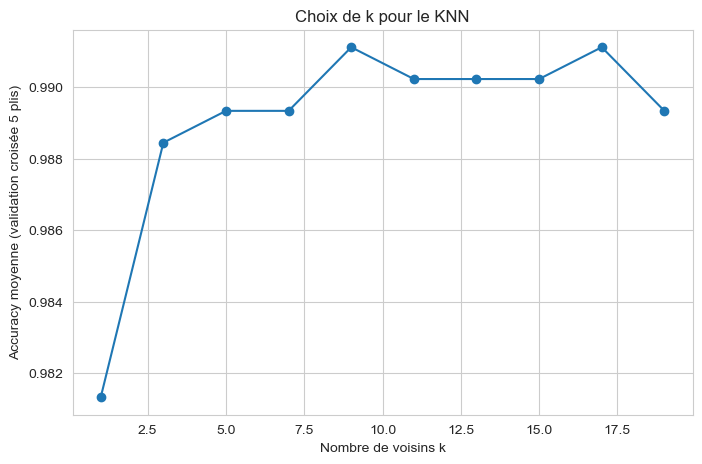

Meilleur k : 9 (accuracy CV = 0.9911)
=== KNN (k=9) ===
Accuracy          : 0.9893
Précision (faux)  : 0.9919
Rappel (faux)     : 0.9760
F1 (faux)         : 0.9839
Matrice de confusion (lignes = réel [Vrai, Faux]) :
[[249   1]
 [  3 122]]


In [16]:
from sklearn.neighbors import KNeighborsClassifier

# On teste k = 1, 3, 5, ... et on garde le meilleur en validation croisée
scores_k = {}
for k in range(1, 21, 2):
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores_k[k] = cross_val_score(knn_k, X_train_std, y_train, cv=5).mean()

plt.figure(figsize=(8, 5))
plt.plot(list(scores_k.keys()), list(scores_k.values()), marker="o")
plt.xlabel("Nombre de voisins k")
plt.ylabel("Accuracy moyenne (validation croisée 5 plis)")
plt.title("Choix de k pour le KNN")
plt.show()

meilleur_k = max(scores_k, key=scores_k.get)
print(f"Meilleur k : {meilleur_k} (accuracy CV = {scores_k[meilleur_k]:.4f})")

knn = KNeighborsClassifier(n_neighbors=meilleur_k)
knn.fit(X_train_std, y_train)
resultats_modeles["KNN"] = evaluer(f"KNN (k={meilleur_k})",
                                   y_test, knn.predict(X_test_std))

### 5.4 Random Forest

chaque arbre pose question et prend la décisions. puis on regroupe le résuktat pour chaque arbre et la majorité permet d  identifier le billet en tant que vrai ou faux.  

La forêt mesure l'**importance de chaque variable** (à quel point elle
aide à bien séparer les classes), ce qui est utile pour l'interprétation.

=== Random Forest ===
Accuracy          : 0.9920
Précision (faux)  : 0.9919
Rappel (faux)     : 0.9840
F1 (faux)         : 0.9880
Matrice de confusion (lignes = réel [Vrai, Faux]) :
[[249   1]
 [  2 123]]
Accuracy en validation croisée (5 plis) : 0.9884 ± 0.0022


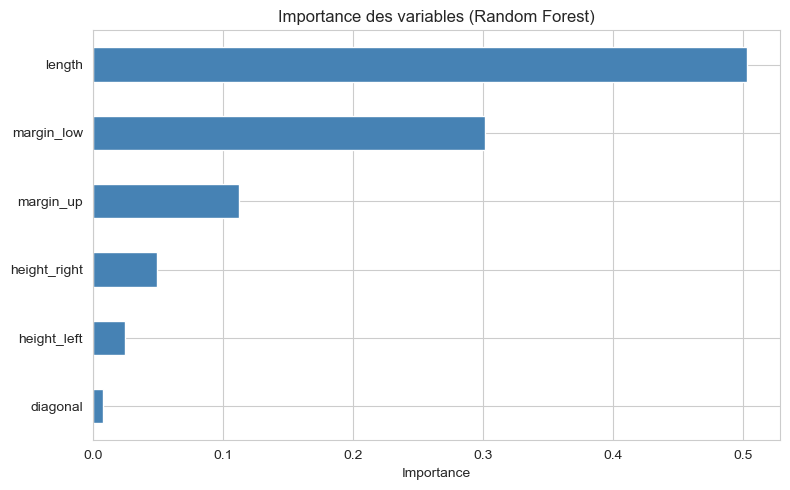

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)  # pas de standardisation nécessaire pour les arbres

resultats_modeles["Random Forest"] = evaluer(
    "Random Forest", y_test, rf.predict(X_test))

cv = cross_val_score(rf, X_train, y_train, cv=5)
print(f"Accuracy en validation croisée (5 plis) : {cv.mean():.4f} ± {cv.std():.4f}")

# Importance des variables
importances = pd.Series(rf.feature_importances_, index=COLS).sort_values()
plt.figure(figsize=(8, 5))
importances.plot.barh(color="steelblue")
plt.title("Importance des variables (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 6. Comparaison des modèles et choix final

In [18]:
# Tableau récapitulatif
comparaison = pd.DataFrame(resultats_modeles).T[
    ["accuracy", "precision_faux", "recall_faux", "f1_faux"]]
comparaison.columns = ["Accuracy", "Précision (faux)",
                       "Rappel (faux)", "F1 (faux)"]
comparaison.round(4)

,Accuracy,Précision (faux),Rappel (faux),F1 (faux)
Régression logistique,0.992,0.991935,0.984,0.987952
K-means,0.986667,0.97619,0.984,0.98008
KNN,0.989333,0.99187,0.976,0.983871
Random Forest,0.992,0.991935,0.984,0.987952


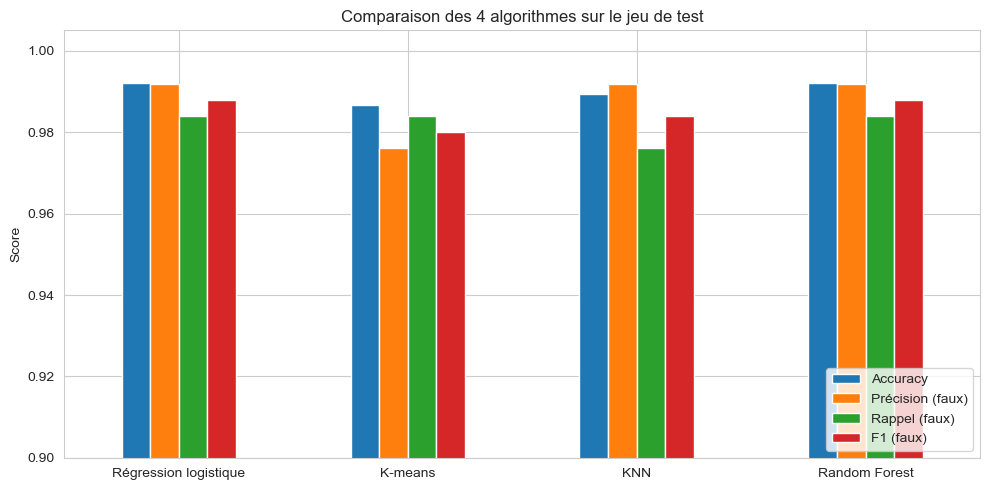

In [19]:
comparaison.plot.bar(figsize=(10, 5), rot=0)
plt.title("Comparaison des 4 algorithmes sur le jeu de test")
plt.ylabel("Score")
plt.ylim(0.9, 1.005)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

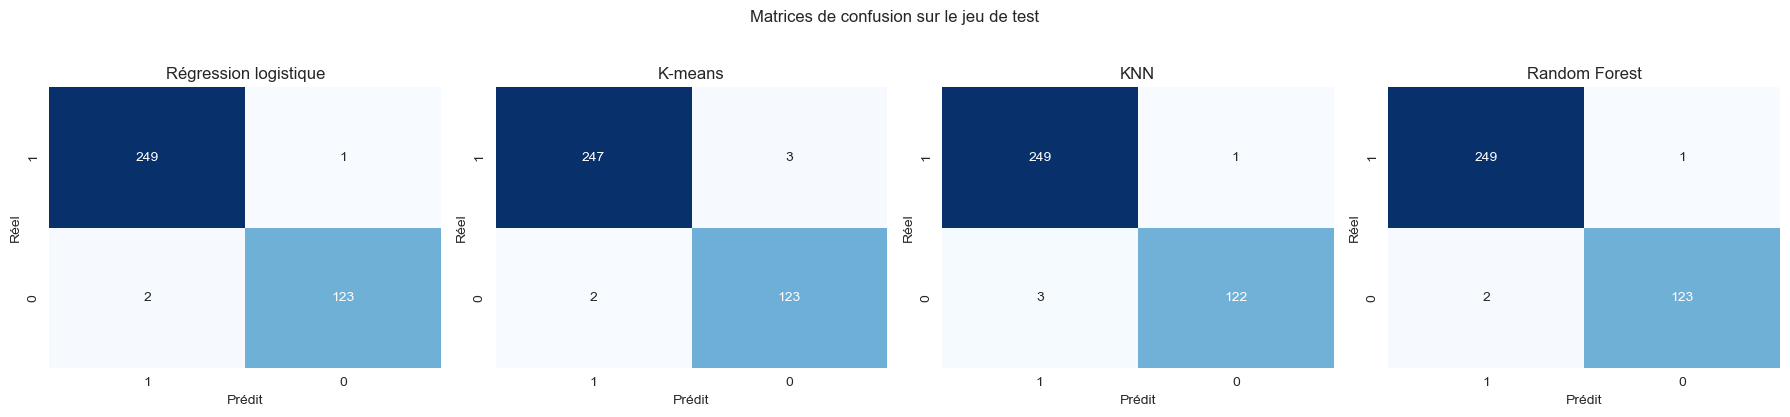

Lecture : 1 = vrai billet, 0 = faux billet. Pour le k-means, les clusters 0/1 sont arbitraires : la correspondance avec les classes a été établie par vote majoritaire sur le jeu d'entraînement.


In [29]:
# Matrices de confusion côte à côte
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nom, m) in zip(axes, resultats_modeles.items()):
    sns.heatmap(m["matrice"], annot=True, fmt="d", cmap="Blues",
                xticklabels=["1", "0"], yticklabels=["1", "0"],
                ax=ax, cbar=False)
    ax.set_title(nom)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
plt.suptitle("Matrices de confusion sur le jeu de test", y=1.03)
plt.tight_layout()
plt.show()
print("Lecture : 1 = vrai billet, 0 = faux billet. " \
"Pour le k-means, les clusters 0/1 sont arbitraires : " \
"la correspondance avec les classes a été établie par vote majoritaire sur le jeu d'entraînement.")

### Courbes ROC

La courbe ROC montre le compromis entre taux de vrais positifs et taux de faux
positifs pour tous les seuils de décision possibles. L'**AUC** (aire sous la
courbe) résume performance : 1 = parfait, 0,5 = hasard. Le k-means
ne fournissant pas de probabilités, il n'apparaît pas sur ce graphique.

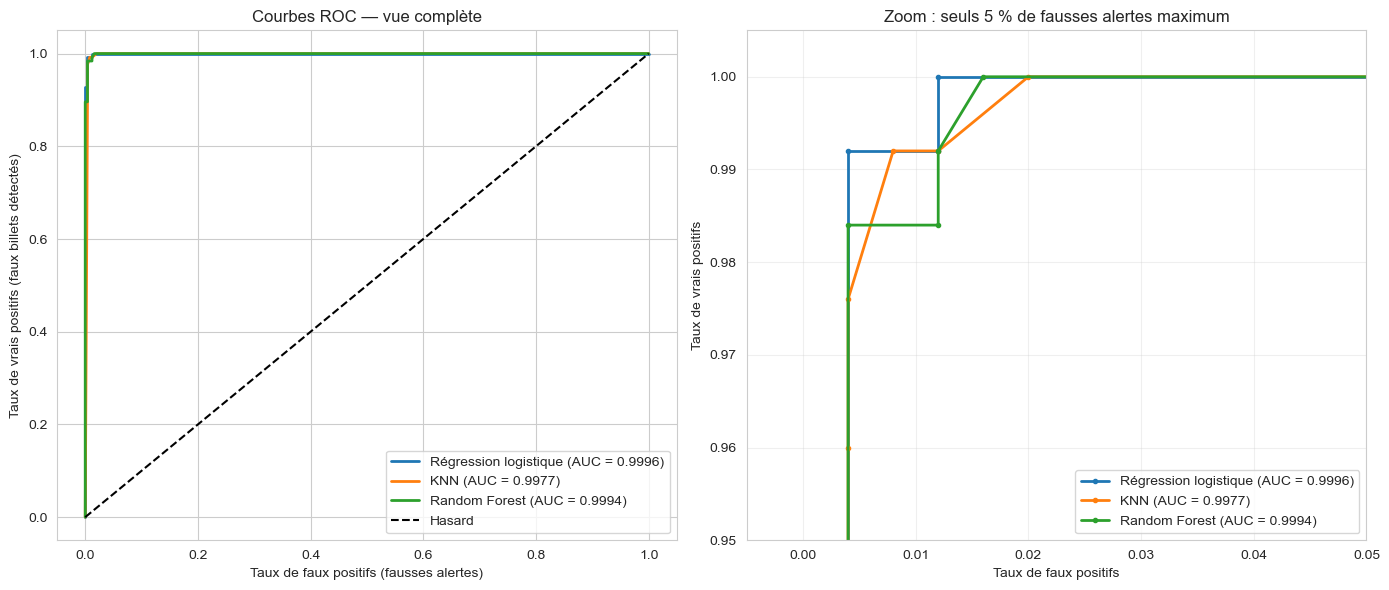

In [21]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
# Courbes ROC : vue complète + zoom sur l'angle utile
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for nom, modele, Xte in [("Régression logistique", logreg, X_test_std),
                          ("KNN", knn, X_test_std),
                          ("Random Forest", rf, X_test)]:
    proba = modele.predict_proba(Xte)[:, list(modele.classes_).index(False)]
    fpr, tpr, _ = roc_curve(y_test, proba, pos_label=False)
    aire = auc(fpr, tpr)

    # À gauche : la vue complète (contexte)
    ax1.plot(fpr, tpr, linewidth=2, label=f"{nom} (AUC = {aire:.4f})")
    # À droite : le zoom sur l'angle où tout se joue
    ax2.plot(fpr, tpr, linewidth=2, marker="o", markersize=3,
             label=f"{nom} (AUC = {aire:.4f})")

# Graphique vue d'ensemble
ax1.plot([0, 1], [0, 1], "k--", label="Hasard")
ax1.set_xlabel("Taux de faux positifs (fausses alertes)")
ax1.set_ylabel("Taux de vrais positifs (faux billets détectés)")
ax1.set_title("Courbes ROC — vue complète")
ax1.legend(loc="lower right")

# Graphique zoom
ax2.set_xlim(-0.005, 0.05)
ax2.set_ylim(0.95, 1.005)
ax2.set_xlabel("Taux de faux positifs")
ax2.set_ylabel("Taux de vrais positifs")
ax2.set_title("Zoom : seuls 5 % de fausses alertes maximum")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Sauvegarde du modèle pour l'application

On ré-entraîne la régression logistique sur les 1 500 billets


In [22]:
import joblib

# Ré-entraînement sur toutes les données disponibles
scaler_final = StandardScaler()
X_std_full = scaler_final.fit_transform(X)
modele_final = LogisticRegression(random_state=42, max_iter=1000)
modele_final.fit(X_std_full, y)

# On sauvegarde tout ce dont l'application aura besoin
joblib.dump({"modele": modele_final,
             "scaler": scaler_final,
             "colonnes": COLS,
             "reg_imputation": reg_imputation,
             "variables_explicatives": variables_explicatives},
            "modele_final.pkl")

print("Modèle sauvegardé dans modele_final.pkl")
print("\nExemple de prédiction sur 3 billets du fichier :")
exemple = X.head(3)
pred = modele_final.predict(scaler_final.transform(exemple))
proba = modele_final.predict_proba(scaler_final.transform(exemple))
for i, (p, pr) in enumerate(zip(pred, proba)):
    print(f"Billet {i+1} : {'VRAI' if p else 'FAUX'} "
          f"(probabilité vrai = {pr.max():.1%})")

Modèle sauvegardé dans modele_final.pkl

Exemple de prédiction sur 3 billets du fichier :
Billet 1 : VRAI (probabilité vrai = 70.4%)
Billet 2 : VRAI (probabilité vrai = 100.0%)
Billet 3 : VRAI (probabilité vrai = 99.8%)


## 8. Zone de test : essayer le modèle sur de nouveaux billets

Le modèle est sauvegardé dans `modele_final_simple.pkl`. On peut donc le
**recharger** et l'essayer sur des billets nouveaux, sans rien ré-entraîner.

**Règle 1:** avant de prédire, il faut appliquer aux nouveaux billets. Exactement les mêmes traitements qu'à l'entraînement :  
1. si `margin_low` manque → on l'estime avec la régression linéaire sauvegardée ;
2. on standardise avec le scaler sauvegardé (celui appris sur les 1 500 billets) ;
3. seulement ensuite on prédit.  

ces 3 étapes dans fonction `predire_billets`.

In [23]:
# On recharge tout le nécessaire depuis le fichier sauvegardé
outils = joblib.load("modele_final.pkl")
modele = outils["modele"]              # la régression logistique entraînée
scaler_charge = outils["scaler"]       # le scaler (moyennes/écarts-type appris)
reg_imp = outils["reg_imputation"]     # la régression pour les margin_low manquants
vars_exp = outils["variables_explicatives"]
colonnes = outils["colonnes"]

def predire_billets(nouveaux):
    """Prend un tableau de nouveaux billets et renvoie VRAI/FAUX + probabilité."""
    nouveaux = nouveaux.copy()

    # 1) Si margin_low manque, on l'estime comme pendant l'entraînement
    masque = nouveaux["margin_low"].isna()
    if masque.any():
        nouveaux.loc[masque, "margin_low"] = reg_imp.predict(
            nouveaux.loc[masque, vars_exp])

    # 2) Standardisation avec le scaler sauvegardé
    X_std = scaler_charge.transform(nouveaux[colonnes].astype(float))

    # 3) Prédiction (True = vrai billet) + probabilité
    predictions = modele.predict(X_std)
    probabilites = modele.predict_proba(X_std).max(axis=1)
    return predictions, probabilites


In [24]:
# Exemple : les mesures d'un billet à tester
billet_test = pd.DataFrame([{
    "diagonal": 171.55,
    "height_left": 103.76,
    "height_right": 104.21,
    "margin_low": 5.11,
    "margin_up": 3.01,
    "length": 111.48,
}])

pred, proba = predire_billets(billet_test)
print("Verdict :", "VRAI BILLET" if pred[0] else "FAUX BILLET",
      f"(confiance : {proba[0]:.1%})")

Verdict : FAUX BILLET (confiance : 99.4%)


In [26]:
#TEST SUR UN FICHIER

import os

# Le nom du fichier à analyser : il suffit de changer cette ligne
nom_fichier = "billets_test.csv"

# Lecture du fichier (séparateur ";" ou ",")
nouveaux = pd.read_csv(nom_fichier, sep=";")
if len(nouveaux.columns) == 1:
    nouveaux = pd.read_csv(nom_fichier, sep=",")

# Prédiction sur tout le fichier
pred, proba = predire_billets(nouveaux)

# On ajoute les résultats au tableau et on affiche
resultats = nouveaux.copy()
resultats["verdict"] = np.where(pred, "VRAI BILLET", "FAUX BILLET")
resultats["confiance"] = (proba * 100).round(1).astype(str) + " %"
print(f"{len(resultats)} billets analysés : "
      f"{int(pred.sum())} vrais, {int((~pred).sum())} faux")
resultats

5 billets analysés : 2 vrais, 3 faux


,diagonal,height_left,height_right,margin_low,margin_up,length,id,verdict,confiance
0,172.09,103.95,103.73,4.39,3.09,113.19,B_1,VRAI BILLET,99.6 %
1,171.52,104.17,104.03,5.27,3.16,111.82,B_2,FAUX BILLET,99.7 %
2,171.78,103.80,103.75,3.81,3.24,113.39,B_3,VRAI BILLET,100.0 %
3,172.02,104.08,103.99,5.57,3.30,111.10,B_4,FAUX BILLET,100.0 %
4,171.79,104.34,104.37,5.00,3.07,111.87,B_5,FAUX BILLET,99.0 %
